In [1]:
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

In [2]:
CRASH_FILE = "data/crashes_amsterdam_classified.csv"
DERTIG_FILE = "data/amsterdam_dertig.json"
TRANSLATION_FILE = "data/road_id_translation.csv"

CHANGED, CONTROL = "50->30", "stayed 50"
BEFORE = ["2021", "2022", "2023"]
AFTER = ["2024", "2025"]

# Chart colours: one per group, text and grid in neutral greys
COLORS = {CHANGED: "#eb6834", CONTROL: "#2a78d6"}
LABELS = {CHANGED: "50 -> 30 km/h", CONTROL: "stayed 50 km/h"}
TEXT, MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"

In [3]:
def style_axes(ax, title, ylabel):
    """Shared chart style: light grid, no top/right border, muted axis text."""
    ax.set_title(title, loc="left", color=TEXT, fontsize=12)
    ax.set_ylabel(ylabel, color=MUTED)
    ax.grid(axis="y", color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False)
    ax.spines[["left", "bottom"]].set_color(GRID)
    ax.tick_params(colors=MUTED)


def mark_change(ax):
    """Dashed line between 2023 and 2024 for the change, and a grey band for 2020 (COVID)."""
    ax.axvline(2023.5, color=MUTED, linestyle="--", linewidth=1)
    ax.text(2023.6, 0.98, "50 -> 30\nDec 2023", transform=ax.get_xaxis_transform(),
            va="top", color=MUTED, fontsize=9)
    ax.axvspan(2019.5, 2020.5, color=GRID, alpha=0.6, linewidth=0)
    ax.text(2020, 0.98, "COVID", transform=ax.get_xaxis_transform(), ha="center", va="top", color=MUTED, fontsize=9)

## 1. Crashes per km of road
Road length per group from `amsterdam_dertig.json`. The changed and unchanged roads differ in length, so crashes per km makes them comparable. Junction crashes count towards the group of the junction.

In [4]:
# Road length per group (Dutch RD coordinates, so lengths are in metres)
dertig = gpd.read_file(DERTIG_FILE).to_crs(28992)
dertig["WVK_ID"] = dertig["WVK_ID"].astype(str)
dertig = dertig.drop_duplicates("WVK_ID")
translation = pd.read_csv(TRANSLATION_FILE, dtype=str)
dertig_group = translation[translation["METHOD"] == "dertig_id"].set_index("ID")["GROUP"]
dertig["GROUP"] = dertig["WVK_ID"].map(dertig_group)

road_km = (dertig.length.groupby(dertig["GROUP"]).sum() / 1000)[[CHANGED, CONTROL]]
road_km.round(0).rename("km")

GROUP
50->30       360.0
stayed 50    277.0
Name: km, dtype: float64

In [5]:
all_crashes = pd.read_csv(CRASH_FILE, dtype=str, keep_default_na=False)
crashes = all_crashes[all_crashes["ROAD_GROUP"].isin([CHANGED, CONTROL])]


def count_crashes(data):
    """Crashes per year (rows) for the changed and the control group (columns)."""
    return pd.crosstab(data["JAAR_VKL"], data["ROAD_GROUP"]).reindex(columns=[CHANGED, CONTROL], fill_value=0)


counts = count_crashes(crashes)
per_km = counts / road_km
per_km.round(2)

ROAD_GROUP,50->30,stayed 50
JAAR_VKL,,
2016,6.12,2.41
2017,6.15,2.66
2018,5.53,2.51
2019,5.16,2.68
2020,3.97,2.14
2021,4.41,2.36
2022,4.94,2.81
2023,4.96,2.79
2024,4.49,2.61


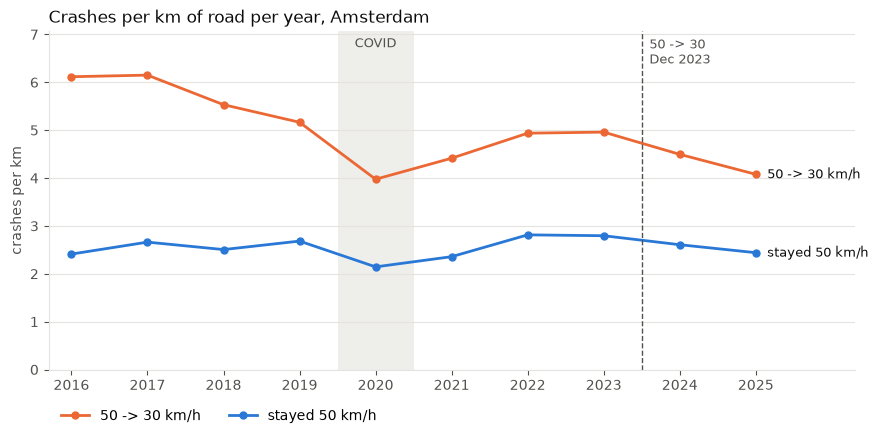

In [6]:
years = per_km.index.astype(int)
fig, ax = plt.subplots(figsize=(9, 4.5))
for group in [CHANGED, CONTROL]:
    ax.plot(years, per_km[group], color=COLORS[group], linewidth=2, marker="o", markersize=5, label=LABELS[group])
    ax.text(years[-1] + 0.15, per_km[group].iloc[-1], LABELS[group], va="center", color=TEXT, fontsize=9)
mark_change(ax)
style_axes(ax, "Crashes per km of road per year, Amsterdam", "crashes per km")
ax.set_ylim(0, per_km.max().max() * 1.15)
ax.set_xticks(years)
ax.set_xlim(years[0] - 0.3, years[-1] + 1.3)
ax.legend(frameon=False, loc="upper left", bbox_to_anchor=(0, -0.08), ncol=2)
plt.tight_layout()
plt.show()

## 2. Did the groups move in parallel before the change?
Difference-in-differences only works if both groups would have moved the same way without the change. Both groups indexed on their 2021-2023 average = 100: before 2024 the lines should run together.

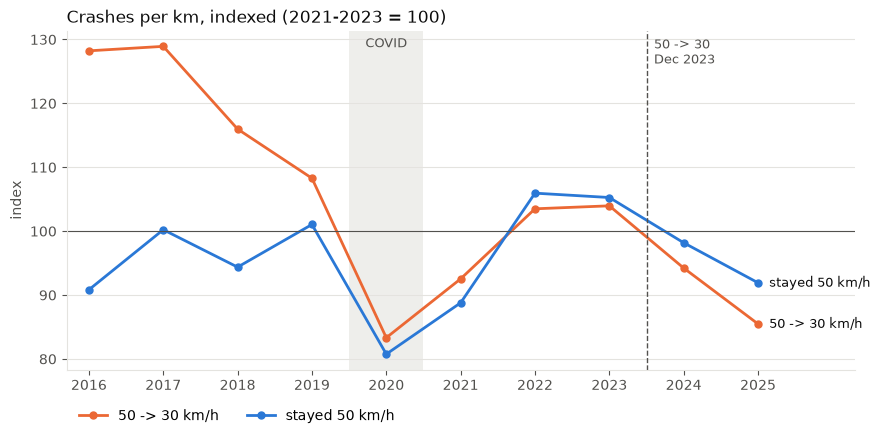

ROAD_GROUP,50->30,stayed 50
JAAR_VKL,,
2016,128.0,91.0
2017,129.0,100.0
2018,116.0,94.0
2019,108.0,101.0
2020,83.0,81.0
2021,93.0,89.0
2022,103.0,106.0
2023,104.0,105.0
2024,94.0,98.0


In [7]:
indexed = per_km / per_km.loc[BEFORE].mean() * 100

fig, ax = plt.subplots(figsize=(9, 4.5))
for group in [CHANGED, CONTROL]:
    ax.plot(years, indexed[group], color=COLORS[group], linewidth=2, marker="o", markersize=5, label=LABELS[group])
    ax.text(years[-1] + 0.15, indexed[group].iloc[-1], LABELS[group], va="center", color=TEXT, fontsize=9)
ax.axhline(100, color=MUTED, linewidth=0.8)
mark_change(ax)
style_axes(ax, "Crashes per km, indexed (2021-2023 = 100)", "index")
ax.set_xticks(years)
ax.set_xlim(years[0] - 0.3, years[-1] + 1.3)
ax.legend(frameon=False, loc="upper left", bbox_to_anchor=(0, -0.08), ncol=2)
plt.tight_layout()
plt.show()

indexed.round(0)

## 3. Before vs after

In [8]:
summary = pd.DataFrame({
    "road km": road_km,
    "crashes before": counts.loc[BEFORE].sum(),
    "crashes after": counts.loc[AFTER].sum(),
    "per km per year before": counts.loc[BEFORE].mean() / road_km,
    "per km per year after": counts.loc[AFTER].mean() / road_km,
})
summary["change (%)"] = (summary["per km per year after"] / summary["per km per year before"] - 1) * 100
summary.round(2)

,road km,crashes before,crashes after,per km per year before,per km per year after,change (%)
50->30,359.56,5145,3082,4.77,4.29,-10.15
stayed 50,276.58,2203,1396,2.66,2.52,-4.95


## 4. Difference-in-differences
Road length and the number of years are the same for both periods, so they cancel out: the ratio is the same for crash counts and crashes per km.

The 95% interval assumes crash counts are Poisson distributed. Real crash counts vary more than that from year to year, so the true interval is wider. The placebo test in step 5 shows how large that year-to-year variation is.

In [9]:
def did(counts, before, after):
    """Difference-in-differences as a ratio, with a 95% interval assuming Poisson counts."""
    b = counts.loc[before].sum()
    a = counts.loc[after].sum()
    ratio = (a[CHANGED] / b[CHANGED]) / (a[CONTROL] / b[CONTROL])
    se = np.sqrt((1 / a + 1 / b).sum())   # standard error of the log ratio
    return pd.Series({"ratio": ratio, "low": ratio * np.exp(-1.96 * se), "high": ratio * np.exp(1.96 * se)})


result = did(counts, BEFORE, AFTER)
print(f"Effect: {result['ratio']:.2f} (95% interval {result['low']:.2f} - {result['high']:.2f})")
print(f"Crashes on the changed roads changed {(result['ratio'] - 1) * 100:+.0f}% compared to the roads that stayed 50")

Effect: 0.95 (95% interval 0.87 - 1.02)
Crashes on the changed roads changed -5% compared to the roads that stayed 50


## 5. Placebo test
The same calculation for periods without a change. If these give 'effects' of the same size as the real one, the real effect does not stand out from the normal year-to-year variation between the groups. 2020 is skipped in all periods.

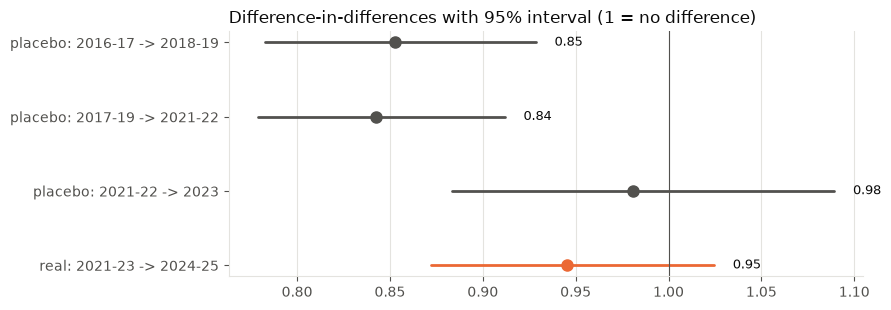

,ratio,low,high
placebo: 2016-17 -> 2018-19,0.85,0.78,0.93
placebo: 2017-19 -> 2021-22,0.84,0.78,0.91
placebo: 2021-22 -> 2023,0.98,0.88,1.09
real: 2021-23 -> 2024-25,0.95,0.87,1.02


In [10]:
periods = {
    "placebo: 2016-17 -> 2018-19": (["2016", "2017"], ["2018", "2019"]),
    "placebo: 2017-19 -> 2021-22": (["2017", "2018", "2019"], ["2021", "2022"]),
    "placebo: 2021-22 -> 2023": (["2021", "2022"], ["2023"]),
    "real: 2021-23 -> 2024-25": (BEFORE, AFTER),
}
placebo = pd.DataFrame({name: did(counts, before, after) for name, (before, after) in periods.items()}).T

fig, ax = plt.subplots(figsize=(9, 3.2))
positions = range(len(placebo))[::-1]
for y, (name, row) in zip(positions, placebo.iterrows()):
    color = COLORS[CHANGED] if name.startswith("real") else MUTED
    ax.plot([row["low"], row["high"]], [y, y], color=color, linewidth=2, solid_capstyle="round")
    ax.plot(row["ratio"], y, "o", color=color, markersize=8)
    ax.text(row["high"] + 0.01, y, f"{row['ratio']:.2f}", va="center", color=TEXT, fontsize=9)
ax.axvline(1, color=MUTED, linewidth=0.8)
ax.set_yticks(list(positions), placebo.index)
style_axes(ax, "Difference-in-differences with 95% interval (1 = no difference)", "")
ax.grid(axis="y", visible=False)
ax.grid(axis="x", color=GRID, linewidth=0.8)
plt.tight_layout()
plt.show()

placebo.round(2)

## 6. Sensitivity
Does the result depend on choices made in the analysis?
- **Before = 2022-2023**: a shorter baseline
- **Segments only / junctions only**: junction crashes get the group of the roads that meet there, which is less exact
- **Without second-pass matches**: leave out crashes grouped by street name or junction location in `wegvakken.ipynb` (about 95% accurate)
- **Unknowns all changed / all stayed 50**: the extreme cases for the crashes without a road group

In [11]:
unknown = all_crashes["ROAD_GROUP"] == "unknown"
second_pass = crashes["MATCH_METHOD"].isin(["street_name", "junction_location"])

sensitivity = pd.DataFrame({
    "main result": did(counts, BEFORE, AFTER),
    "before = 2022-2023": did(counts, ["2022", "2023"], AFTER),
    "segments only": did(count_crashes(crashes[crashes["LOCATION_TYPE"] == "segment"]), BEFORE, AFTER),
    "junctions only": did(count_crashes(crashes[crashes["LOCATION_TYPE"] == "junction"]), BEFORE, AFTER),
    "without second-pass matches": did(count_crashes(crashes[~second_pass]), BEFORE, AFTER),
    "unknowns all changed": did(count_crashes(all_crashes.assign(
        ROAD_GROUP=all_crashes["ROAD_GROUP"].mask(unknown, CHANGED))), BEFORE, AFTER),
    "unknowns all stayed 50": did(count_crashes(all_crashes.assign(
        ROAD_GROUP=all_crashes["ROAD_GROUP"].mask(unknown, CONTROL))), BEFORE, AFTER),
}).T
sensitivity.round(2)

,ratio,low,high
main result,0.95,0.87,1.02
before = 2022-2023,0.96,0.88,1.05
segments only,0.91,0.81,1.03
junctions only,0.98,0.88,1.10
without second-pass matches,0.96,0.88,1.04
unknowns all changed,0.96,0.89,1.04
unknowns all stayed 50,0.91,0.85,0.99


## Conclusion
After the change, crashes per km fell by 10% on the roads that went from 50 to 30 km/h, against 5% on the roads that stayed 50. That is a 5% larger decrease on the changed roads (difference-in-differences 0.95, 95% interval 0.87-1.02).

But this is not convincing evidence of a greater effect:
- The placebo test shows differences of this size without any change.
- The sensitivity checks all point the same way (0.91-0.96), but none of them is clearly below 1 except the extreme case where all unknown crashes are on roads that stayed 50.

Answer to the subquestion: in the first two years after the change, crashes on the roads that went from 50 to 30 km/h decreased slightly more than on the roads that stayed 50, but the difference is small and within the normal year-to-year variation between the two groups. There is no clear evidence of a greater effect on the changed roads.

**Limitations**
- Crashes per km, not per vehicle-km: there are no traffic counts per road. If traffic moved from the 30 roads to the roads that stayed 50, the control group is affected too, which would make the difference look larger than it is.
- The city chose which roads to change, and some were redesigned at the same time.
- Only two years after the change, and no dates in the data, so 2023 is counted as before although the limit changed in December 2023.
- About 1% of crashes have no road group, and about 5% of the second-pass matches may be in the wrong group (see the sensitivity check).